# Piloto: selección de puntos de colocación con historia del residuo

Una semilla de Burgers compara aleatorio uniforme, Sobol, RAD, POD sin centrar + QR y PCA centrado con la media explícita + QR. Todos los métodos comparten un calentamiento uniforme, inicialización, estado de Adam, muestras supervisadas y tamaño/frecuencia de actualización del lote físico. El piloto es exploratorio, no una comparación estadística.

In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent: ROOT = ROOT.parent
OUT = ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_pilot_1_seed_v1'
SUMMARY = json.loads((OUT / 'summary.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(OUT / 'metrics.csv')
trace = pd.read_csv(OUT / 'validation_trajectories.csv')
display(pd.Series({k: SUMMARY[k] for k in ['seed','candidate_count','history_snapshots','history_matrix_shape','wall_seconds']}))

## Qué se observa antes de entrenar con los métodos

La matriz R tiene una fila por punto candidato y una columna por snapshot del residuo. POD usa R sin centrar; PCA resta la media temporal y conserva esa media como una dirección adicional antes de pivotar QR. El piloto retiene modos por energía cuadrática acumulada (σ²). El artículo QR-DEIM usa SVD y QR con pivoteo, y actualiza/poda puntos adaptativamente; esta primera versión mantiene fijo el tamaño activo y no implementa poda.

## Resultados del piloto (una semilla)

| Método | RMSE prueba | L2 relativo | Residuo independiente | Tiempo pipeline (s) |
|---|---:|---:|---:|---:|
| Aleatorio uniforme | 0.3585 | 0.5686 | 0.2083 | 3.503 |
| Sobol | 0.3623 | 0.5746 | 0.1913 | 3.052 |
| RAD | 0.4030 | 0.6393 | 0.1628 | 3.065 |
| POD + QR | 0.3647 | 0.5784 | 0.1867 | 3.023 |
| PCA centrado + media + QR | 0.3669 | 0.5820 | 0.1841 | 3.044 |

La selección QR usó inicialmente 3 índices para POD y 5 para PCA con media; el límite configurado es 32. Los espacios restantes hasta 128 puntos activos se completan con Sobol. Esta cuenta pequeña refleja el rango de la historia y no es el tamaño total del lote.

## Residuo, espectro y modos

**Magnitud del residuo en candidatos**

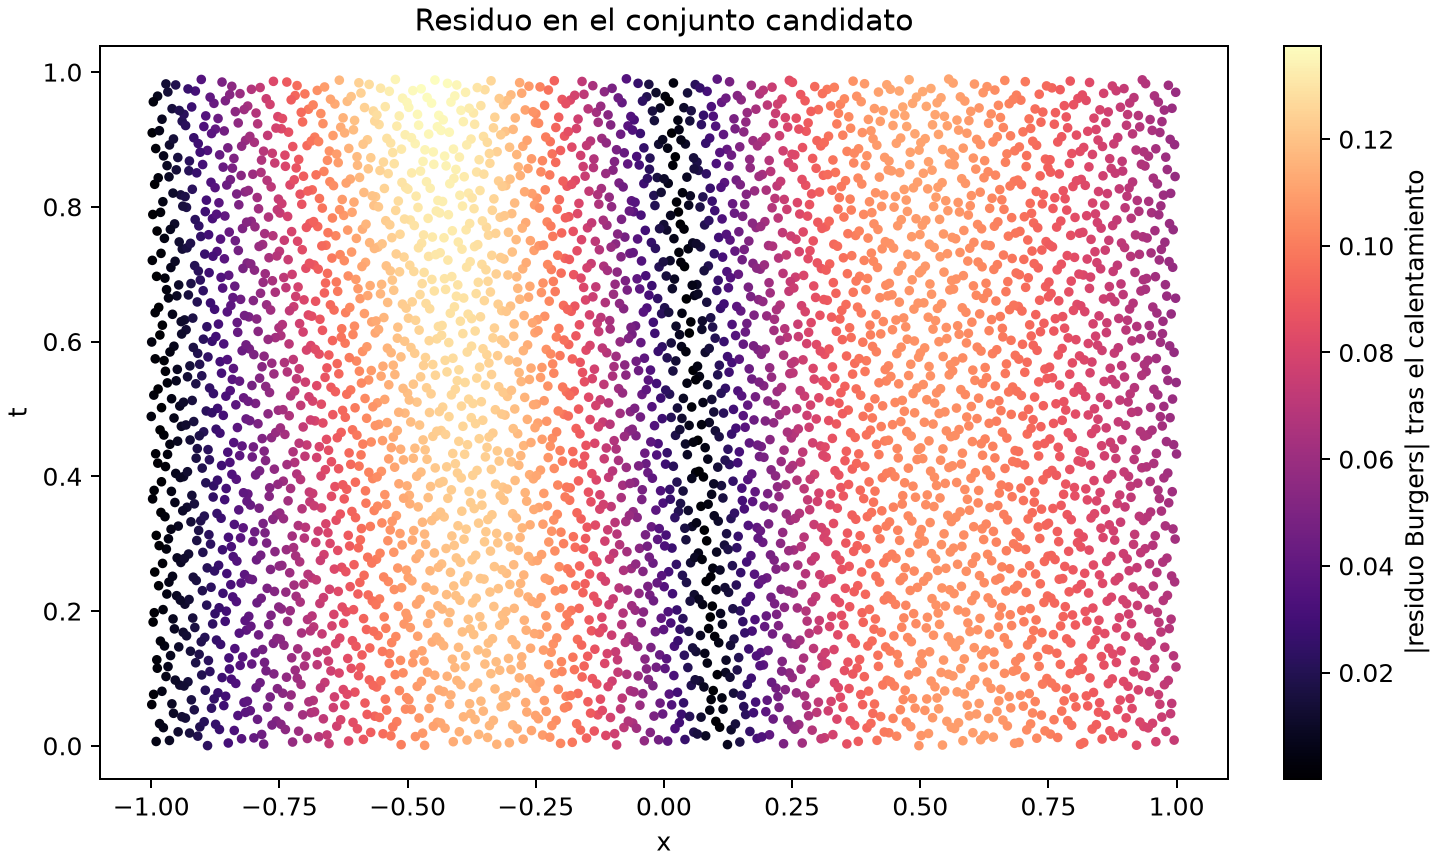

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_pilot_1_seed_v1/residual_map.png'), format='png', embed=True))


**Espectro singular y energía retenida**

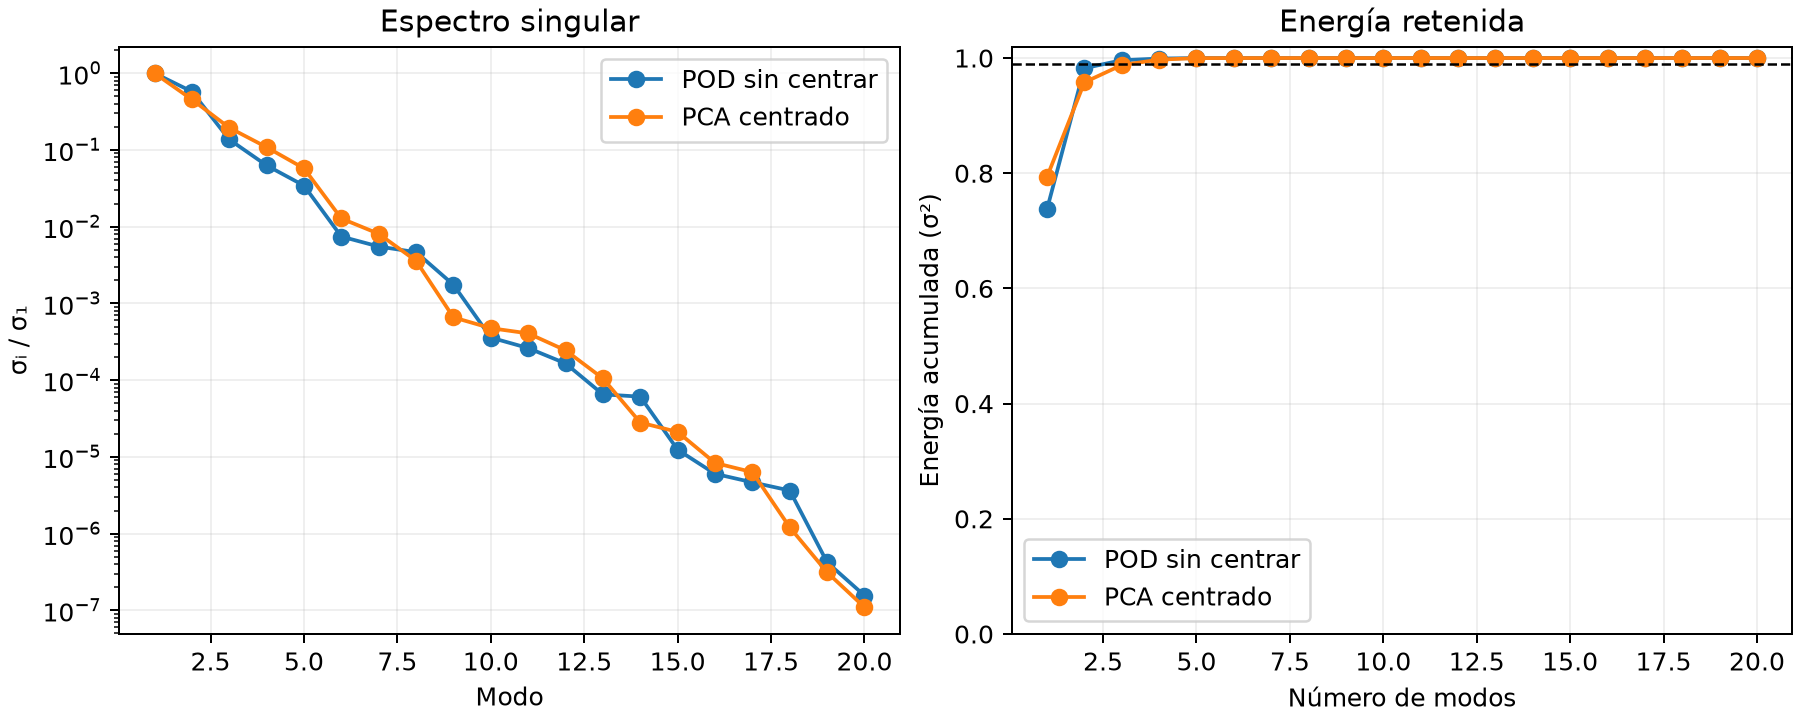

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_pilot_1_seed_v1/singular_spectrum.png'), format='png', embed=True))


**Primeros modos POD de la historia residual**

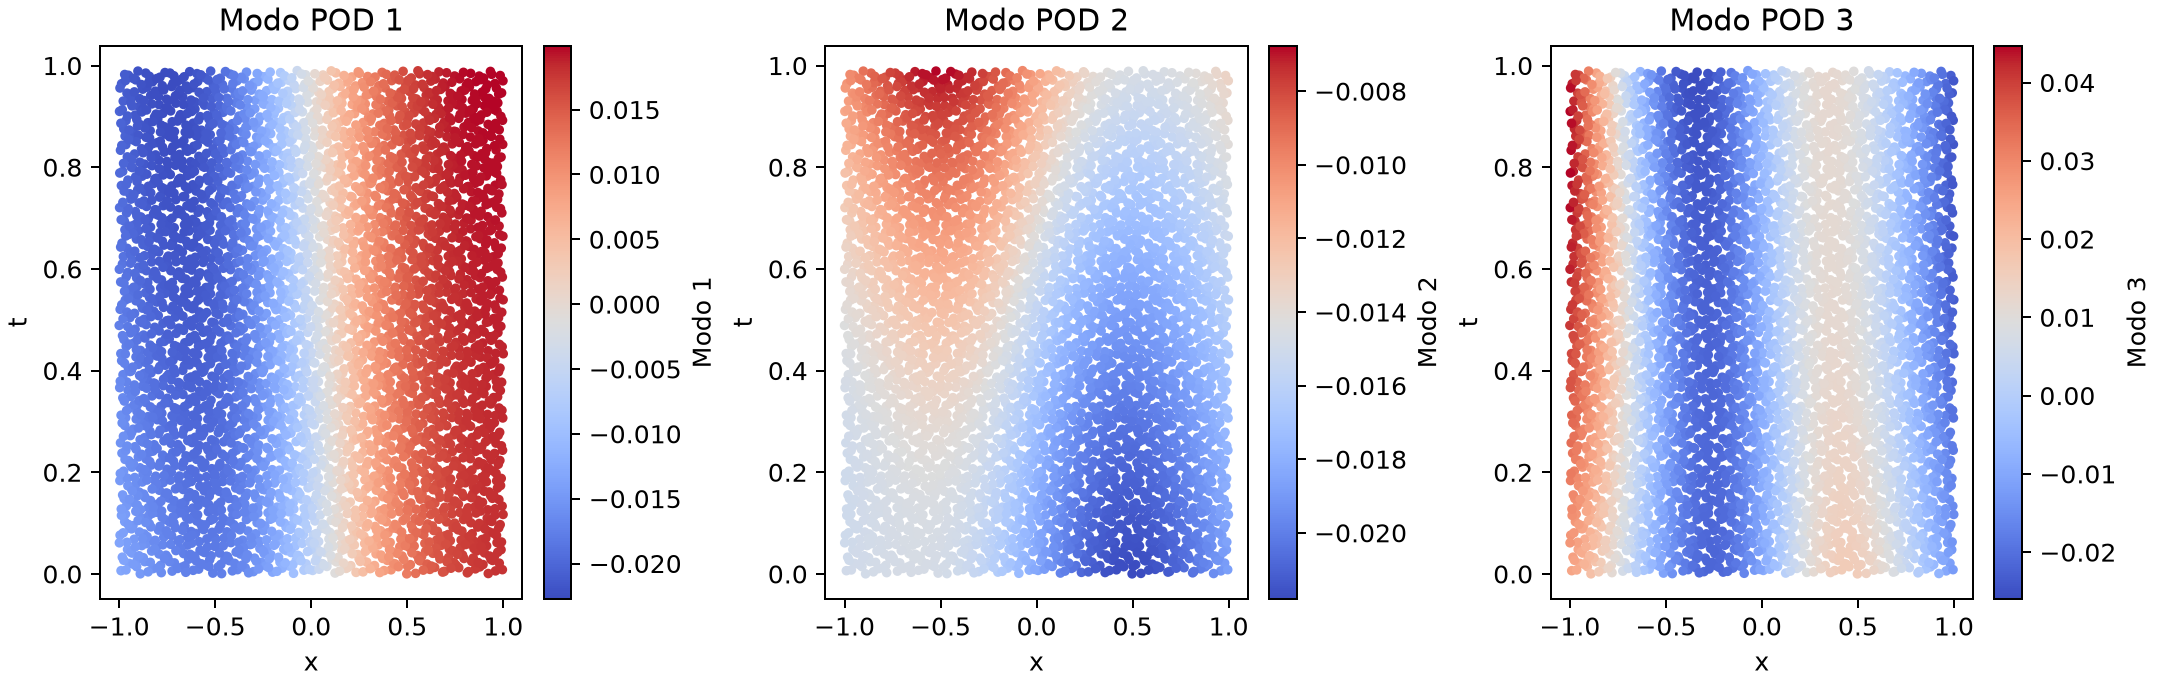

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_pilot_1_seed_v1/residual_modes.png'), format='png', embed=True))


**Lotes activos y puntos elegidos por QR en rojo**

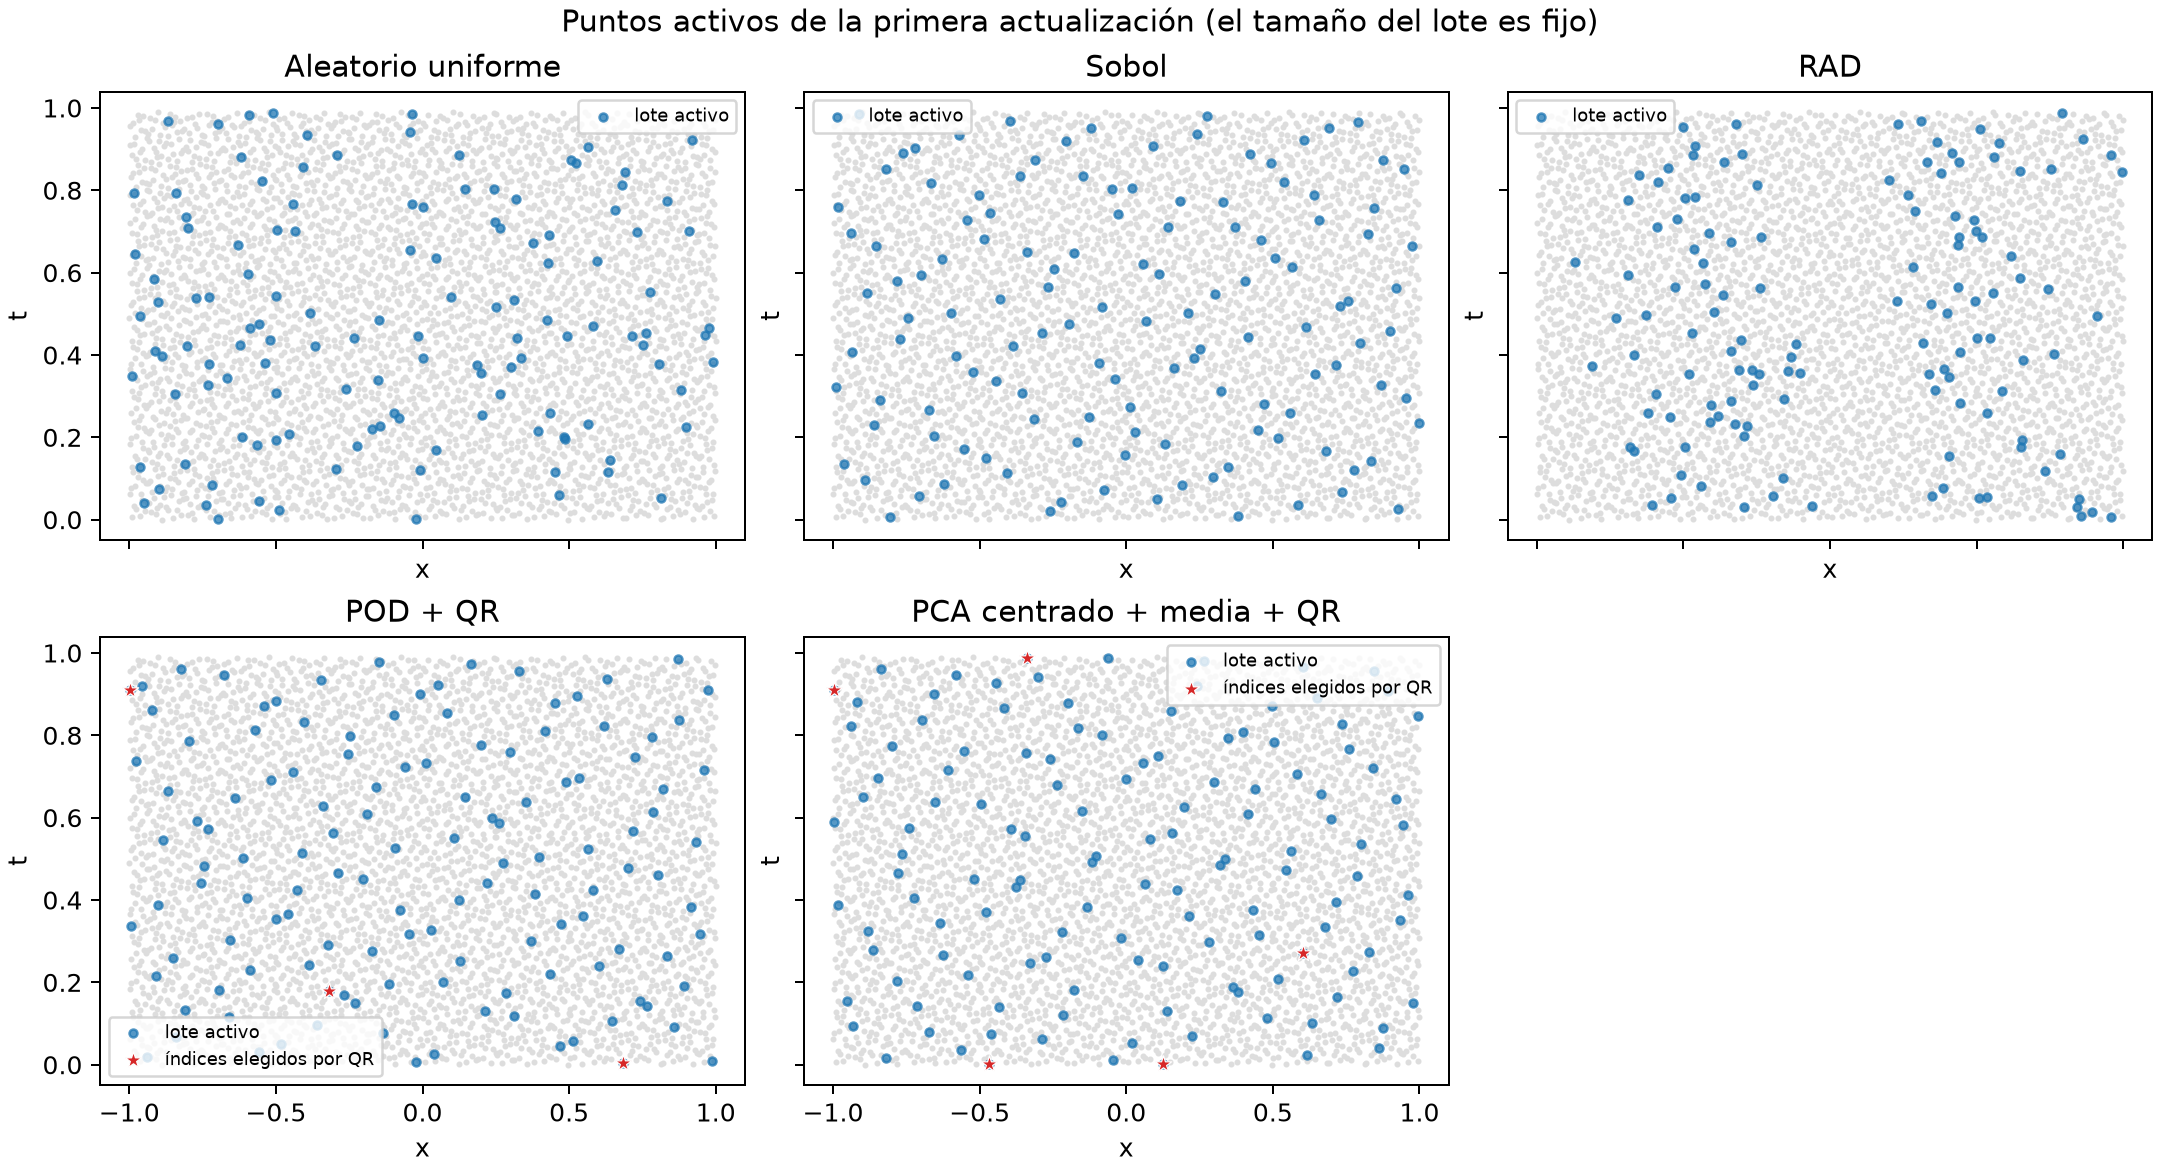

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_pilot_1_seed_v1/selected_points.png'), format='png', embed=True))


## Comportamiento de entrenamiento y evaluación independiente

El residuo físico se evalúa en un conjunto Sobol independiente del candidato y del entrenamiento. Error de solución, residuo, condición inicial y frontera se reportan por separado. Los tiempos incluyen las actualizaciones de selección; se informa aparte el calentamiento compartido. La compilación común de JAX se resuelve antes de medir cada método. La comparación por igual número de pasos es el resultado principal de este piloto; la comparación a igual precisión requiere más semillas y una regla de objetivo fijada antes de analizar resultados.

**RMSE de validación durante el entrenamiento**

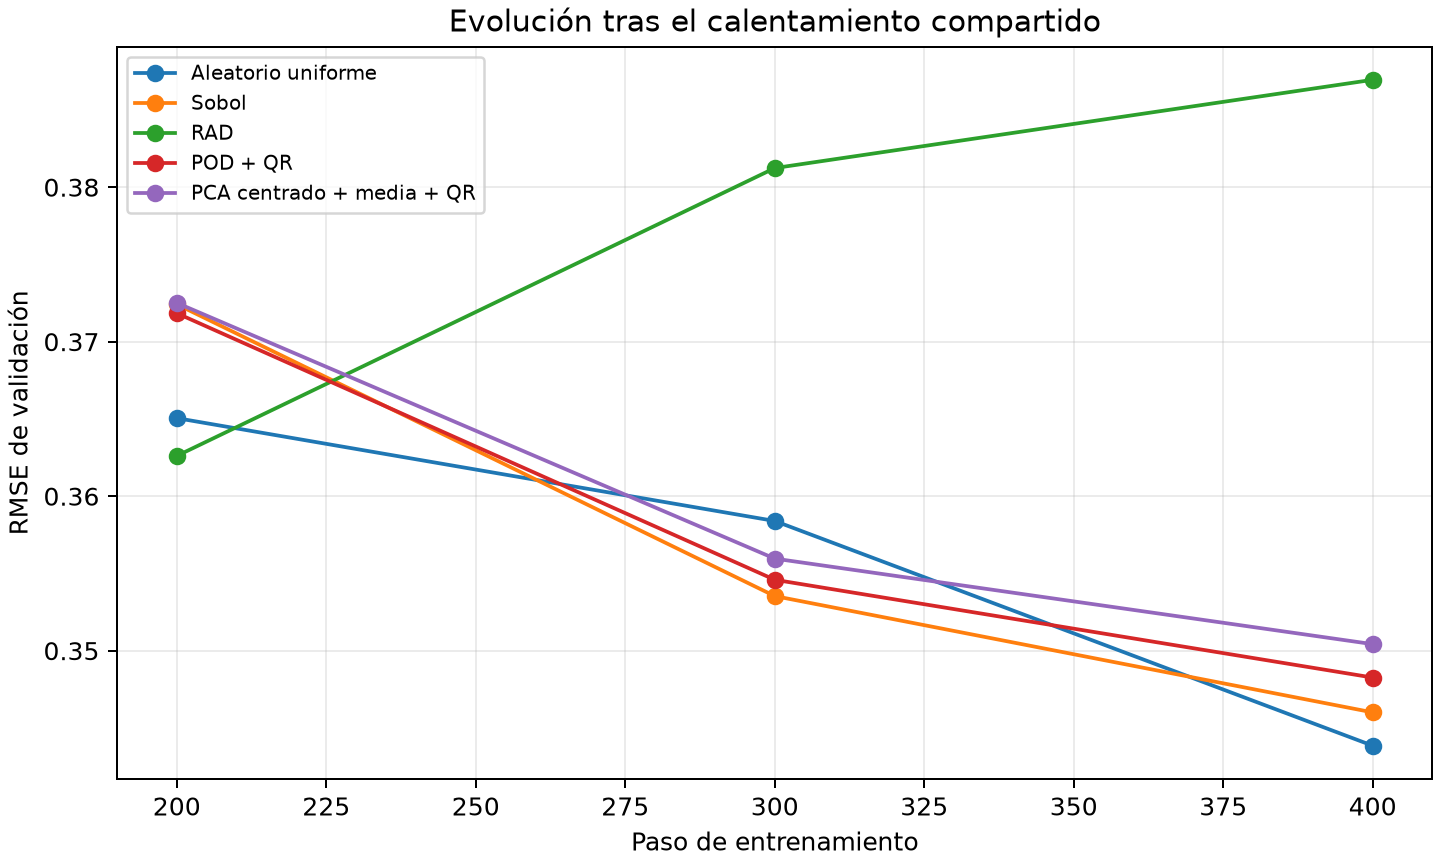

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_pilot_1_seed_v1/validation_rmse.png'), format='png', embed=True))


In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent: ROOT = ROOT.parent
OUT = ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_pilot_1_seed_v1'
SUMMARY = json.loads((OUT / 'summary.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(OUT / 'metrics.csv')
trace = pd.read_csv(OUT / 'validation_trajectories.csv')
display(metrics.sort_values('test_relative_l2').reset_index(drop=True))
display(trace.pivot(index='step', columns='label', values='validation_rmse'))